---
title: "M2HATS ISS 915 MHz wind profiler: daily time-height curtains"
author: Jacquelyn Witte
date: 2026-11-18
---

# Daily time-height curtains from the M2HATS 915 MHz wind profiler

[M2HATS](https://www.eol.ucar.edu/field_projects/m2hats) was a 2023 field campaign in which the
NSF NCAR Earth Observing Laboratory (EOL) deployed its **Integrated Sounding System (ISS)**.
One ISS instrument is a **radar wind profiler**: a vertically pointing radar that measures
echoes from turbulence in clear air. From the strength and Doppler shift of those echoes it
derives vertical motion and horizontal wind at a range of heights above the site, many times
an hour. The 915 MHz profiler samples the lower atmosphere (the boundary layer) at finer
vertical resolution than the [449 MHz profiler](./eol_m2hats_prof449.ipynb), which reaches higher.

GDEX serves the 915 MHz profiler record as [dataset d361535](https://gdex.ucar.edu/datasets/d361535/).
It has **one Zarr store per day**, each with three groups, one per data product:

| Group | What it holds |
|---|---|
| `moments` | Per-dwell Doppler moments, including signal-to-noise ratio (`sigNoiseRatio`) and vertical velocity (`vel`) |
| `winds_nima` | 30-minute consensus winds from the NIMA processing |
| `winds_reprocessed` | 30-minute reprocessed consensus winds |

This notebook opens one day and draws a three-panel **curtain plot**: time on the x-axis,
height on the y-axis, colored by

1. **Signal-to-noise ratio** (dB), which shows where the radar has a usable return,
2. **Vertical velocity** (m/s), which shows updrafts and downdrafts,
3. **Wind speed** (m/s), overlaid with wind barbs showing direction.

:::{note} New to Zarr?
Each daily store is in [Zarr format](../docs/zarr_format.md). Opening a group with
`xr.open_zarr()` returns an ordinary `xarray.Dataset`, so everything after that works
the same as with NetCDF.
:::

:::{seealso} How to cite these data
NSF/NCAR EOL Integrated Sounding System Team. 2026. *M2HATS: ISS Radar 915 MHz Wind Profiler Data.*
NSF National Center for Atmospheric Research. https://gdex.ucar.edu/datasets/d361535/. Accessed dd mmm yyyy.

EOL also asks you to cite the source data:
[doi:10.26023/ZH7Z-GRWB-AV0F](https://doi.org/10.26023/ZH7Z-GRWB-AV0F).
:::

[![Binder](https://binder.k8s.ucar.edu/badge_logo.svg)](https://binder.k8s.ucar.edu/v2/gh/NCAR/gdex-examples/main?labpath=notebooks/eol_m2hats_prof915.ipynb)

*Run this notebook interactively on CIRRUS BinderHub.*

In [1]:
import os
import re
from glob import glob
from urllib.parse import urljoin

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import requests
import xarray as xr

## Find the daily zarr stores

:::{important} No edits needed
The cells below **automatically select the data path** — POSIX where `/gdex/data` is
mounted (NCAR HPC, CIRRUS Binder), otherwise OSDF over the network. **You don't
need to change anything.**
:::

In [2]:
DSID = "d361535"   # GDEX dataset ID: M2HATS ISS 915 MHz wind profiler

posix_dir = f"/gdex/data/{DSID}/zarr/"
osdf_dir  = f"https://osdf-director.osg-htc.org/ncar/gdex/{DSID}/zarr/"


def list_https_stores(base_url):
    """Return the URLs of the .zarr stores in an HTTPS directory listing."""
    r = requests.get(base_url, timeout=60)
    r.raise_for_status()
    return sorted(urljoin(base_url, h) for h in re.findall(r'href="([^"?]+\.zarr/?)', r.text))

In [3]:
# Use POSIX access when the archive is mounted, otherwise OSDF
if os.path.isdir(posix_dir):
    BASE   = posix_dir
    stores = sorted(glob(os.path.join(posix_dir, "*.zarr")))
else:
    BASE   = osdf_dir
    stores = list_https_stores(osdf_dir)

if not stores:
    raise ValueError(f"No Zarr stores found under {BASE}")

names = [os.path.basename(s.rstrip("/")) for s in stores]
print(f"Access: {'POSIX mount' if BASE == posix_dir else 'OSDF (remote)'}")
print(f"Found {len(stores)} daily stores: {names[0]} … {names[-1]}")

Access: POSIX mount
Found 61 daily stores: m2hats_eol-iss_windradar_915MHz_20230725_v1.zarr … m2hats_eol-iss_windradar_915MHz_20230924_v1.zarr


## 1. Configuration

#### Settings to edit
Edit the values below before running.
`WINDS_GROUP` selects whether panel 3 uses the `winds_nima` or `winds_reprocessed` winds.
The optional time window lets you zoom into part of the day.

In [5]:
# Settings to edit
DATE        = "20230909"     # YYYYMMDD; must be within the range printed above
WINDS_GROUP = "winds_nima"   # winds for panel 3: "winds_nima" or "winds_reprocessed"
CAMPAIGN    = "M2HATS"

# Optional time window; leave all three as None to plot the whole day
PLOT_HOURS = None   # last N hours of the day, e.g. 4
PLOT_START = None   # or an explicit window, e.g. "2023-09-09 12:00"
PLOT_END   = None   #                       e.g. "2023-09-09 16:30"

# Daily store for the chosen date
store_name = f"{CAMPAIGN.lower()}_eol-iss_windradar_915MHz_{DATE}_v1.zarr"
if store_name not in names:
    raise ValueError(f"No store for {DATE}. Choose a date from {names[0]} to {names[-1]}.")
ZARR_STORE = f"{BASE}{store_name}"

# Color limits
SNR_VMIN, SNR_VMAX = -20, 20   # panel 1: signal-to-noise ratio, dB
VEL_VMAX           =  10       # panel 2: vertical velocity, m/s (symmetric ±)
WSPD_VMAX          =  15       # panel 3: wind speed, m/s

# Output
SAVE_FIGURE = False   # True saves a PNG to OUTPUT_DIR; False only displays it
OUTPUT_DIR  = "."

## 2. Opening the Zarr store

The daily store contains three groups:
- `moments` — Doppler data (~3944 time steps per day, one per radar dwell)
- `winds_reprocessed` or `winds_nima` — 30-minute averaged winds (48 time steps per day)

`consolidated=True` reads the single `.zmetadata` summary file at the store root
rather than opening each variable's metadata file one by one — faster, especially
over a networked filesystem. 

The `height` coordinate is 2-D `(time, height)` in all groups. Heights are constant
across time for this instrument, so `height[0, :]` gives a representative 1-D
height vector suitable for the y-axis.

In [6]:
# Open both groups — each returns a standard xarray Dataset
ds_mom   = xr.open_zarr(ZARR_STORE, group='moments',   consolidated=True)
ds_winds = xr.open_zarr(ZARR_STORE, group=WINDS_GROUP, consolidated=True)

# Apply optional time range filter
if PLOT_HOURS is not None:
    t_end   = ds_mom['time'].values[-1]
    t_start = t_end - np.timedelta64(int(PLOT_HOURS * 3600), 's')
    ds_mom   = ds_mom.sel(time=slice(t_start, t_end))
    ds_winds = ds_winds.sel(time=slice(t_start, t_end))
elif PLOT_START is not None and PLOT_END is not None:
    ds_mom   = ds_mom.sel(time=slice(np.datetime64(PLOT_START), np.datetime64(PLOT_END)))
    ds_winds = ds_winds.sel(time=slice(np.datetime64(PLOT_START), np.datetime64(PLOT_END)))

## 3. Plotting the curtain

A **curtain plot** stacks time along the x-axis and height along the y-axis,
showing how a variable evolves through the day at each altitude level.
`pcolormesh` draws the filled color grid; wind barbs are overlaid on panel 3
using subsampled `u` and `v` components converted from m/s to knots (the
meteorological convention for barb plots).

The moments group has ~3944 time steps and the winds group has 48 — they use
separate time arrays but share the same x-axis via `sharex=True`. `pcolormesh`
handles the different resolutions correctly because each panel passes its own
time array. 

Wind barbs are subsampled to ~60 time × 15 height points for readability — the
full-resolution data would produce an unreadable dense grid of barbs.

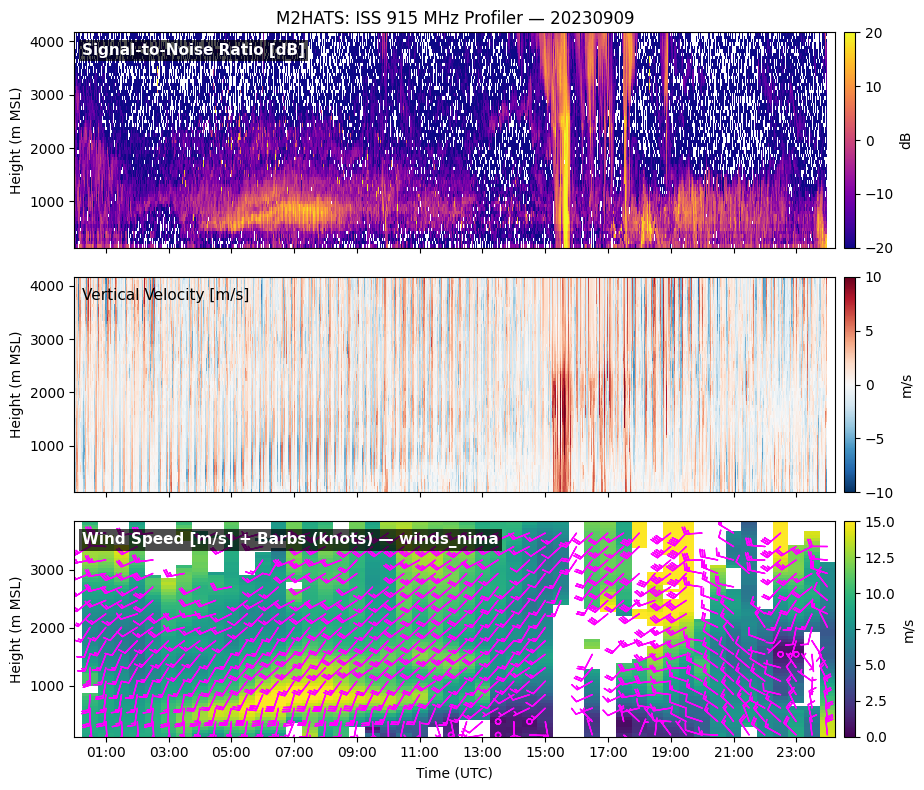

In [7]:
# Extract arrays — height is 2-D (time, height); use first time step as representative 1-D vector
time_mom   = ds_mom['time'].values
height_mom = ds_mom['height'].values[0, :]
snr        = ds_mom['sigNoiseRatio'].values   # (time, height)
vel        = ds_mom['vel'].values             # (time, height)

time_w     = ds_winds['time'].values
height_w   = ds_winds['height'].values[0, :]
wspd       = ds_winds['wspd'].values          # (time, height), m/s

# Use wind components by group and correct convention for reprocessed winds.
if WINDS_GROUP == 'winds_nima':
    u = ds_winds['u_classicC'].values
    v = ds_winds['v_classicC'].values
elif WINDS_GROUP == 'winds_reprocessed':
    # Reprocessed u/v are opposite the wind-from convention used by matplotlib barbs.
    u = -ds_winds['u'].values
    v = -ds_winds['v'].values
else:
    u = ds_winds['u'].values
    v = ds_winds['v'].values

# Wind barb subsampling — target ~60 time × 15 height points regardless of resolution
n_time_winds, n_height_winds = u.shape
t_step   = max(1, n_time_winds   // 60)
h_step   = max(1, n_height_winds // 15)

# [::t_step] takes every t_step-th element along that axis
# [::h_step] takes every h_step-th element along that axis
time_sub   = time_w[::t_step]
height_sub = height_w[::h_step]
u_sub      = u[::t_step, ::h_step]
v_sub      = v[::t_step, ::h_step]

# Convert u, v from m/s to knots — meteorological convention for wind barbs
MS_TO_KNOTS = 1.94384
u_kts      = (u_sub * MS_TO_KNOTS)
v_kts      = (v_sub * MS_TO_KNOTS)
# Repeat time and height values across height columns and time rows to create a 2-D grid for wind barb plotting
T_grid, H_grid       = np.meshgrid(time_sub, height_sub, indexing='ij')

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
fig.subplots_adjust(hspace=0.06)

# Panel 1 — Signal-to-noise ratio
# The transpose is important: the snr array is shaped [time, height], 
# but pcolormesh expects [y, x] = [height, time], so .T flips it to align with axes.
pc1 = axes[0].pcolormesh(time_mom, height_mom, snr.T,
                          cmap='plasma', vmin=SNR_VMIN, vmax=SNR_VMAX, shading='auto')
fig.colorbar(pc1, ax=axes[0], label='dB', pad=0.01)
axes[0].set_ylabel('Height (m MSL)')
axes[0].set_title(f'{CAMPAIGN}: ISS 915 MHz Profiler — {DATE}', fontsize=12)
bbox=dict(facecolor='black', alpha=0.7, pad=2, edgecolor='none')
axes[0].text(0.01, 0.95, 'Signal-to-Noise Ratio [dB]', transform=axes[0].transAxes,
             va='top', fontsize=11, fontweight='bold', color='white', bbox=bbox)

# Panel 2 — vertical velocity
pc2 = axes[1].pcolormesh(time_mom, height_mom, vel.T,
                          cmap='RdBu_r', vmin=-VEL_VMAX, vmax=VEL_VMAX, shading='auto')
fig.colorbar(pc2, ax=axes[1], label='m/s', pad=0.01)
axes[1].set_ylabel('Height (m MSL)')
axes[1].text(0.01, 0.95, 'Vertical Velocity [m/s]', transform=axes[1].transAxes,
             va='top', fontsize=11)

# Panel 3 — Wind speed background + wind barbs (barbs in knots; background in m/s)
pc3 = axes[2].pcolormesh(time_w, height_w, wspd.T,
                          cmap='viridis', vmin=0, vmax=WSPD_VMAX, shading='auto')
fig.colorbar(pc3, ax=axes[2], label='m/s', pad=0.01)
axes[2].barbs(T_grid.flatten(), H_grid.flatten(), u_kts.flatten(), v_kts.flatten(), length=5, linewidth=1, color='magenta')
axes[2].set_ylabel('Height (m MSL)')
axes[2].set_xlabel('Time (UTC)')
axes[2].text(0.01, 0.95, f'Wind Speed [m/s] + Barbs (knots) — {WINDS_GROUP}', 
             transform=axes[2].transAxes,
             va='top', fontsize=11, fontweight='bold', color='white', bbox=bbox)


# Shared x-axis formatting applied to bottom panel only
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
axes[2].xaxis.set_major_locator(mdates.HourLocator(interval=2))
fig.autofmt_xdate(rotation=0, ha='center')

fig.tight_layout()

if SAVE_FIGURE:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    out_path = os.path.join(OUTPUT_DIR, f'{CAMPAIGN}_prof915_{DATE}_curtain.png')
    fig.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f'Saved: {out_path}')
else:
    plt.show()